# 4. Динамика по годам и сезонность

Данные: `OSHA_db`, 105 996 тяжёлых травм (январь 2015 – ноябрь 2025). SQL-запросы — `SQL/04_years.sql`.

**2025 год неполный** (по 30.11.2025), поэтому годы сравниваются по среднему числу случаев в месяц, а месяцы и дни недели — по среднему числу случаев **в день** (месяцы разной длины).

Что добавляет Python к SQL-результатам:
- проверка значимости изменений между периодами и трендов тяжести;
- сезонность: профиль по месяцам и временам года, разложение ряда (STL), проверки χ² и Краскела–Уоллиса;
- какие причины травм дают сезонные пики (жара, лёд и снег, падения …);
- дни недели.

In [1]:
import os
if not os.path.isdir("src"):  # ноутбук запущен из notebooks/, а не из Analysis/
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy import stats

from src.db import query
from src.viz import set_style, tr, finish, barh_ranked, wrap, LANGS, TABLES_DIR, MAIN, ACCENT, SERIES
from src.stats import num, cramers_v, share_ci, rank_by_title
from src.labels import (sector_code, SECTORS, MONTHS, SEASONS, MONTH_TO_SEASON, WEEKDAYS,
                        EVENT_DIVISIONS, nature_category)
from statsmodels.tsa.seasonal import STL

set_style()
TABLES_DIR.mkdir(exist_ok=True)

## 4.0. Исходные данные и календарь

Календарь нужен, чтобы знать, сколько дней каждого месяца и дня недели попало в период наблюдения.

In [2]:
cases = query("""
    SELECT i.id,
           i.event_date,
           i.severity_code,
           i.event_code,
           i.naics_code,
           s.title  AS source,
           s2.title AS secondary,
           n.title  AS nature
    FROM injuries i
    JOIN source_lookup s       ON s.code  = i.source_code
    LEFT JOIN source_lookup s2 ON s2.code = i.secondary_source_code
    JOIN nature_lookup n       ON n.code  = i.nature_code
""", )
cases["event_date"] = pd.to_datetime(cases["event_date"])
cases["year"] = cases["event_date"].dt.year
cases["month"] = cases["event_date"].dt.month
cases["season"] = cases["month"].map(MONTH_TO_SEASON)
cases["weekday"] = cases["event_date"].dt.dayofweek + 1
cases["event_div"] = cases["event_code"].astype(str).str[0]
cases["sector"] = cases["naics_code"].map(sector_code)
cases["hospitalization"] = (cases["severity_code"] & 4) > 0
cases["amputation"] = (cases["severity_code"] & 2) > 0

# календарь периода наблюдения
days = pd.DataFrame({"date": pd.date_range(cases["event_date"].min(), cases["event_date"].max(), freq="D")})
days["year"], days["month"] = days["date"].dt.year, days["date"].dt.month
days["season"] = days["month"].map(MONTH_TO_SEASON)
days["weekday"] = days["date"].dt.dayofweek + 1

N = len(cases)
print(f"Случаев: {num(N)}, период: {cases['event_date'].min():%d.%m.%Y} – {cases['event_date'].max():%d.%m.%Y}, дней: {num(len(days))}")

Случаев: 105 996, период: 01.01.2015 – 30.11.2025, дней: 3 987


## 4.1. Случаи по годам

Среднее в месяц делает 2025 год сравнимым с остальными. Проверяем, значимо ли снижение после 2020 года: t-критерий Уэлча для средних месячных чисел случаев 2015–2019 и 2021–2025 (2020 — год пандемии — исключён из обоих периодов).

In [3]:
monthly = cases.groupby(["year", "month"]).size().rename("cases").reset_index()
years = monthly.groupby("year").agg(cases=("cases", "sum"), months=("cases", "size"))
years["avg_per_month"] = years["cases"] / years["months"]
years["pct_change_avg"] = 100 * years["avg_per_month"].pct_change()
years["pct_of_period"] = 100 * years["cases"] / N

years.round(2).to_csv(TABLES_DIR / "04_1_cases_by_year.csv", encoding="utf-8-sig")

before = monthly.loc[monthly["year"].between(2015, 2019), "cases"]
after = monthly.loc[monthly["year"].between(2021, 2025), "cases"]
t, p = stats.ttest_ind(before, after, equal_var=False)
print(f"Среднее в месяц: 2015–2019 = {before.mean():.1f}, 2021–2025 = {after.mean():.1f} "
      f"({100 * (after.mean() / before.mean() - 1):+.1f}%), t Уэлча = {t:.2f}, p = {p:.2e}")
years.round(1)

Среднее в месяц: 2015–2019 = 876.3, 2021–2025 = 754.3 (-13.9%), t Уэлча = 8.59, p = 8.43e-14


,cases,months,avg_per_month,pct_change_avg,pct_of_period
year,,,,,
2015,9823,12,818.6,NaN,9.3
2016,10084,12,840.3,2.7,9.5
2017,10445,12,870.4,3.6,9.9
2018,11156,12,929.7,6.8,10.5
2019,11071,12,922.6,-0.8,10.4
2020,8915,12,742.9,-19.5,8.4
2021,8703,12,725.2,-2.4,8.2
2022,9110,12,759.2,4.7,8.6
2023,8943,12,745.2,-1.8,8.4


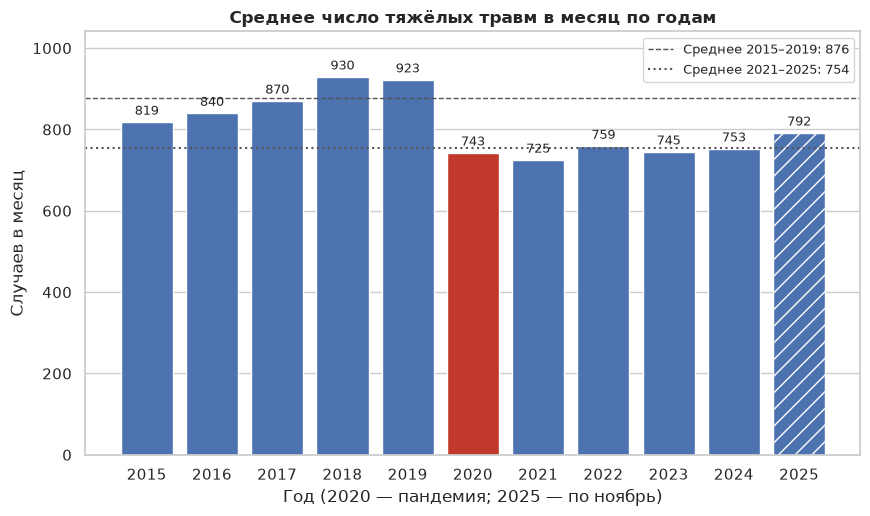

In [4]:
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 5.5))
    colors = [MAIN] * len(years)
    colors[list(years.index).index(2020)] = ACCENT
    bars = ax.bar(years.index, years["avg_per_month"], color=colors)
    bars[-1].set_hatch("//")
    bars[-1].set_edgecolor("white")
    ax.bar_label(bars, labels=[f"{v:.0f}" for v in years["avg_per_month"]], padding=3, fontsize=9)
    ax.axhline(before.mean(), color="#555555", ls="--", lw=1,
               label=tr(f"Среднее 2015–2019: {before.mean():.0f}", f"Mean 2015–2019: {before.mean():.0f}", lang))
    ax.axhline(after.mean(), color="#555555", ls=":", lw=1.5,
               label=tr(f"Среднее 2021–2025: {after.mean():.0f}", f"Mean 2021–2025: {after.mean():.0f}", lang))
    ax.legend(loc="upper right", fontsize=9)
    ax.set_title(tr("Среднее число тяжёлых травм в месяц по годам",
                    "Average number of severe injuries per month by year", lang))
    ax.set_xlabel(tr("Год (2020 — пандемия; 2025 — по ноябрь)", "Year (2020 — pandemic; 2025 — through November)", lang))
    ax.set_ylabel(tr("Случаев в месяц", "Cases per month", lang))
    ax.set_xticks(years.index)
    ax.set_ylim(0, years["avg_per_month"].max() * 1.12)
    ax.grid(axis="x", visible=False)
    finish(fig, "04_1_cases_by_year", lang)

## 4.2. Тяжесть последствий по годам

Доли госпитализаций и ампутаций с 95% ДИ; χ² — меняется ли доля ампутаций от года к году.

In [5]:
rows = []
for y, g in cases.groupby("year"):
    for col in ["hospitalization", "amputation"]:
        pct, lo, hi = share_ci(g[col].sum(), len(g))
        rows.append({"year": y, "outcome": col, "cases": len(g), "pct": pct, "ci_low": lo, "ci_high": hi})
sev_year = pd.DataFrame(rows)
sev_year.round(2).to_csv(TABLES_DIR / "04_2_severity_by_year.csv", index=False, encoding="utf-8-sig")

for col in ["hospitalization", "amputation"]:
    chi2, p, dof, v, _ = cramers_v(pd.crosstab(cases["year"], cases[col]))
    s = sev_year[sev_year["outcome"] == col]
    lr = stats.linregress(s["year"], s["pct"])
    print(f"{col:<16} χ² = {chi2:.1f}, df = {dof}, p = {p:.3f}, V = {v:.3f}; "
          f"тренд {lr.slope:+.2f} п.п. в год (p = {lr.pvalue:.3f})")
sev_year.pivot(index="year", columns="outcome", values="pct").round(2)

hospitalization  χ² = 31.2, df = 10, p = 0.001, V = 0.017; тренд +0.14 п.п. в год (p = 0.030)
amputation       χ² = 28.0, df = 10, p = 0.002, V = 0.016; тренд -0.10 п.п. в год (p = 0.197)


outcome,amputation,hospitalization
year,,
2015,27.51,79.66
2016,26.74,80.47
2017,27.00,80.35
2018,25.73,80.96
2019,25.62,81.28
2020,26.25,81.29
2021,26.27,81.43
2022,26.27,82.22
2023,27.08,81.34


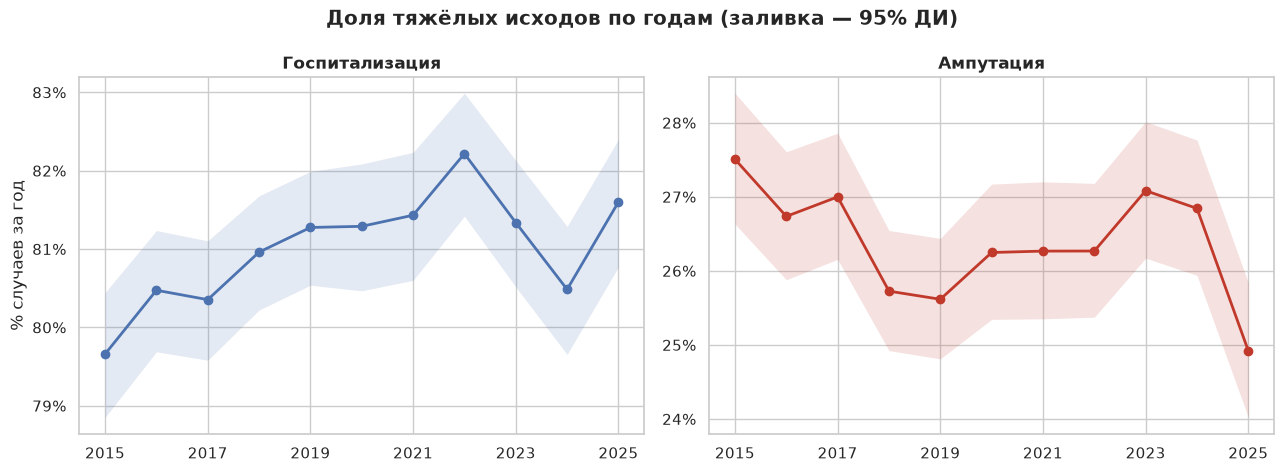

In [6]:
for lang in LANGS:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, col, color in zip(axes, ["hospitalization", "amputation"], [MAIN, ACCENT]):
        s = sev_year[sev_year["outcome"] == col]
        ax.fill_between(s["year"], s["ci_low"], s["ci_high"], color=color, alpha=0.15, lw=0)
        ax.plot(s["year"], s["pct"], marker="o", color=color, lw=2)
        ax.set_title(tr(*{"hospitalization": ("Госпитализация", "Hospitalization"),
                          "amputation": ("Ампутация", "Amputation")}[col], lang))
        ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
        ax.set_xticks(s["year"][::2])
    axes[0].set_ylabel(tr("% случаев за год", "% of cases in year", lang))
    fig.suptitle(tr("Доля тяжёлых исходов по годам (заливка — 95% ДИ)",
                    "Share of severe outcomes by year (band — 95% CI)", lang), fontweight="bold")
    fig.tight_layout()
    finish(fig, "04_2_severity_by_year", lang)

## 4.3. Месяц × год

В SQL (4.3) — число случаев. Здесь — среднее число случаев **в день** (поправка на длину месяца); декабрь 2025 года в данные не входит.

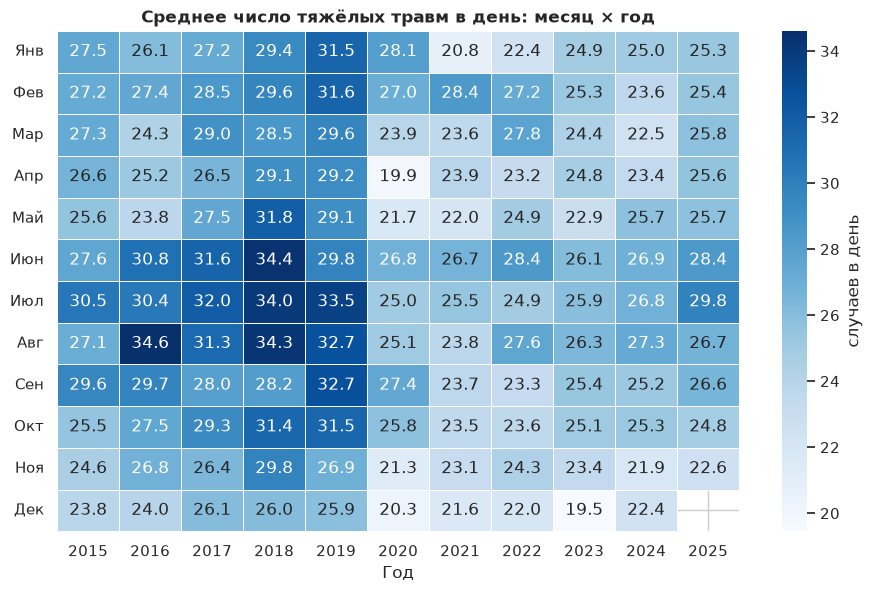

In [7]:
month_days = days.groupby(["year", "month"]).size()
rate = (cases.groupby(["year", "month"]).size() / month_days).unstack("year")
rate.index = [MONTHS[m][0] for m in rate.index]
rate.round(2).to_csv(TABLES_DIR / "04_3_cases_per_day_month_year.csv", encoding="utf-8-sig")

for lang in LANGS:
    r = rate.copy()
    r.index = [MONTHS[m][0 if lang == "ru" else 1] for m in range(1, 13)]
    fig, ax = plt.subplots(figsize=(11, 6.5))
    sns.heatmap(r, annot=True, fmt=".1f", cmap="Blues", linewidths=0.5, linecolor="white", ax=ax,
                cbar_kws={"label": tr("случаев в день", "cases per day", lang)})
    ax.set_title(tr("Среднее число тяжёлых травм в день: месяц × год",
                    "Average severe injuries per day: month × year", lang))
    ax.set_xlabel(tr("Год", "Year", lang))
    ax.set_ylabel("")
    plt.setp(ax.get_yticklabels(), rotation=0)
    finish(fig, "04_3_month_year_heatmap", lang)

## 4.4. Годы × крупнейшие секторы экономики

SQL 4.4 даёт абсолютные числа. Для сравнения динамики секторов разного размера — индекс: среднее в месяц в 2015 году = 100.

In [8]:
main_sectors = ["23", "31-33", "42", "44-45", "48-49", "56", "62"]
sec_year = pd.crosstab(cases["year"], cases["sector"])[main_sectors].div(years["months"], axis=0)
index = 100 * sec_year / sec_year.loc[2015]
sec_year.round(1).to_csv(TABLES_DIR / "04_4_sectors_by_year_per_month.csv", encoding="utf-8-sig")
index.round(1).set_axis([SECTORS[s][0] for s in main_sectors], axis=1)

,Строительство,Обрабатывающая промышленность,Оптовая торговля,Розничная торговля,Транспорт и складирование,"Адм. услуги, утилизация отходов","Здравоохранение, соц. помощь"
year,,,,,,,
2015,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2016,109.1,98.3,106.4,112.8,108.8,90.0,109.4
2017,108.8,100.1,111.0,107.5,109.7,105.4,109.1
2018,115.1,105.4,119.4,123.0,115.5,116.3,123.1
2019,114.3,101.6,126.7,132.4,117.4,112.9,124.2
2020,101.1,82.7,100.2,106.9,98.3,92.1,93.4
2021,89.3,86.0,102.5,101.2,99.3,81.9,92.9
2022,88.6,86.1,114.1,108.1,105.0,90.9,98.6
2023,95.0,85.3,99.6,105.5,98.8,84.9,90.0


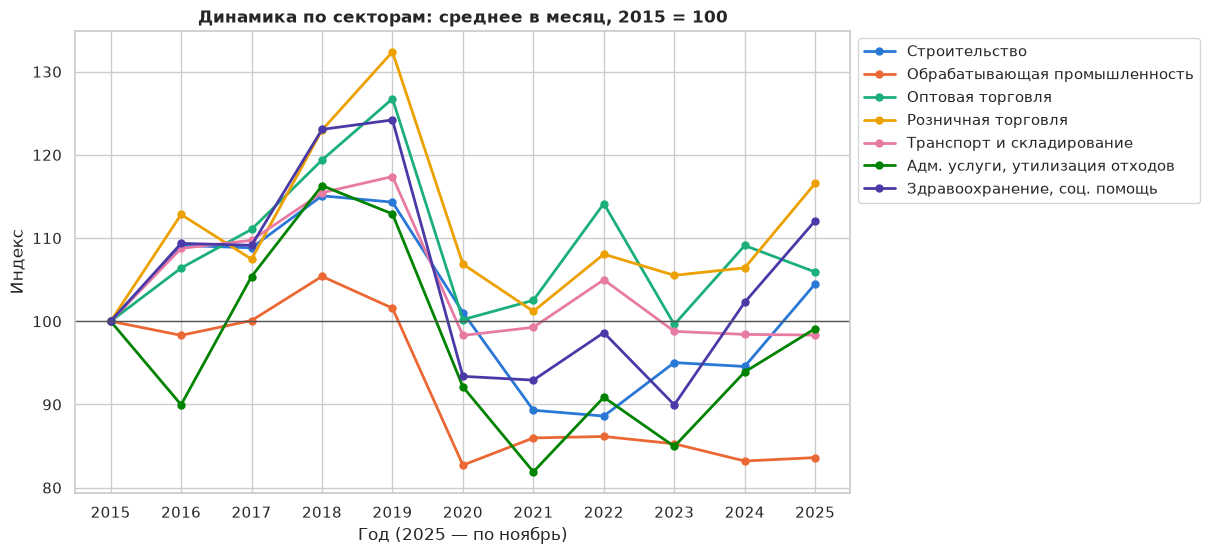

In [9]:
for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(10, 6))
    for s, color in zip(main_sectors, SERIES):
        ax.plot(index.index, index[s], marker="o", ms=5, color=color, lw=2, label=SECTORS[s][k])
    ax.axhline(100, color="#555555", lw=1)
    ax.set_title(tr("Динамика по секторам: среднее в месяц, 2015 = 100",
                    "Trend by sector: cases per month, 2015 = 100", lang))
    ax.set_xlabel(tr("Год (2025 — по ноябрь)", "Year (2025 — through November)", lang))
    ax.set_ylabel(tr("Индекс", "Index", lang))
    ax.set_xticks(index.index)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    finish(fig, "04_4_sectors_index", lang)

## 4.5. Сезонность по месяцам

Для каждого месяца — среднее число случаев в день по 11 годам (декабрь — по 10) и 95% ДИ по годам. Сезонный индекс = уровень месяца / средний уровень × 100.

Проверка: критерий согласия χ² — распределены ли случаи по месяцам пропорционально числу дней (гипотеза «нет сезонности»).

In [10]:
ym = (cases.groupby(["year", "month"]).size() / month_days).dropna().rename("per_day").reset_index()
prof = ym.groupby("month")["per_day"].agg(["mean", "std", "count"])
prof["ci"] = stats.t.ppf(0.975, prof["count"] - 1) * prof["std"] / np.sqrt(prof["count"])
prof["season"] = prof.index.map(MONTH_TO_SEASON)
prof["seasonal_index"] = 100 * prof["mean"] / prof["mean"].mean()

obs = cases.groupby("month").size()
exp = days.groupby("month").size() / len(days) * N
chi2, p = stats.chisquare(obs, exp)
print(f"Равномерность по месяцам (с учётом числа дней): χ² = {chi2:.1f}, df = 11, p = {p:.2e}")
print(f"Пик: {MONTHS[prof['mean'].idxmax()][0]} ({prof['seasonal_index'].max():.0f}), "
      f"минимум: {MONTHS[prof['mean'].idxmin()][0]} ({prof['seasonal_index'].min():.0f})")

prof.round(2).to_csv(TABLES_DIR / "04_5_monthly_profile.csv", encoding="utf-8-sig")
prof.round(2)

Равномерность по месяцам (с учётом числа дней): χ² = 439.5, df = 11, p = 2.47e-87
Пик: Июл (109), минимум: Дек (87)


,mean,std,count,ci,season,seasonal_index
month,,,,,,
1,26.20,3.04,11,2.04,winter,98.63
2,27.40,2.19,11,1.47,winter,103.13
3,26.07,2.47,11,1.66,spring,98.14
4,25.24,2.68,11,1.80,spring,95.00
5,25.52,3.05,11,2.05,spring,96.07
6,28.87,2.56,11,1.72,summer,108.67
7,28.96,3.45,11,2.31,summer,109.01
8,28.80,3.76,11,2.52,summer,108.41
9,27.25,2.81,11,1.89,autumn,102.59


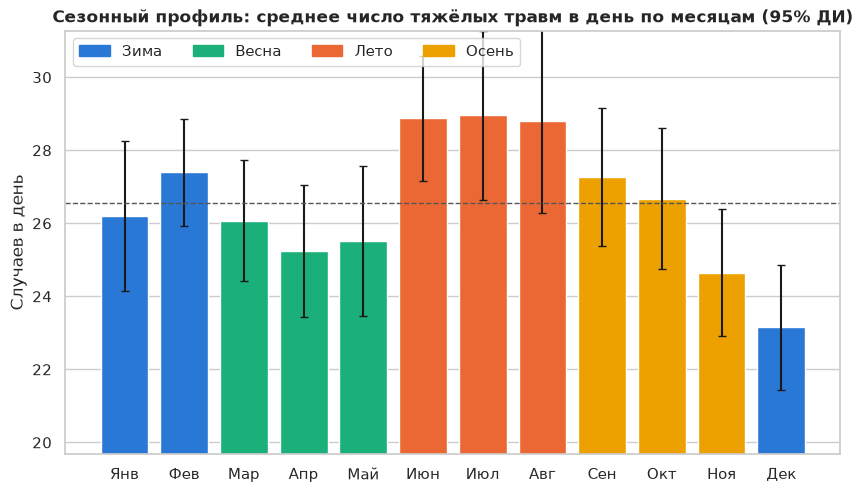

In [11]:
SEASON_COLORS = {"winter": SERIES[0], "spring": SERIES[2], "summer": SERIES[1], "autumn": SERIES[3]}
for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.bar(prof.index, prof["mean"], yerr=prof["ci"], capsize=3,
           color=[SEASON_COLORS[s] for s in prof["season"]])
    ax.axhline(prof["mean"].mean(), color="#555555", ls="--", lw=1)
    ax.set_xticks(prof.index, [MONTHS[m][k] for m in prof.index])
    ax.set_ylim(prof["mean"].min() * 0.85, prof["mean"].max() * 1.08)
    ax.set_title(tr("Сезонный профиль: среднее число тяжёлых травм в день по месяцам (95% ДИ)",
                    "Seasonal profile: average severe injuries per day by month (95% CI)", lang))
    ax.set_ylabel(tr("Случаев в день", "Cases per day", lang))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in SEASON_COLORS.values()],
              labels=[SEASONS[s][k] for s in SEASON_COLORS], loc="upper left", ncols=4)
    ax.grid(axis="x", visible=False)
    finish(fig, "04_5_monthly_profile", lang)

## 4.6. Времена года

Метеорологические сезоны: зима — декабрь–февраль, весна — март–май, лето — июнь–август, осень — сентябрь–ноябрь. Сравнение — по среднему числу случаев в день. Критерий Краскела–Уоллиса проверяет, различается ли уровень по сезонам (единица наблюдения — месяц конкретного года, 131 месяц). Тяжесть по сезонам — доля ампутаций и госпитализаций с 95% ДИ.

In [12]:
season_days = days.groupby("season").size()
seas = cases.groupby("season").agg(cases=("id", "size"), amputations=("amputation", "sum"),
                                   hospitalized=("hospitalization", "sum"))
seas["days"] = season_days
seas["per_day"] = seas["cases"] / seas["days"]
seas["vs_mean_pct"] = 100 * (seas["per_day"] / (N / len(days)) - 1)
seas["pct_amputation"] = 100 * seas["amputations"] / seas["cases"]
seas["pct_hospitalized"] = 100 * seas["hospitalized"] / seas["cases"]
seas = seas.loc[list(SEASONS)]
seas.insert(0, "season_ru", [SEASONS[s][0] for s in seas.index])

ym["season"] = ym["month"].map(MONTH_TO_SEASON)
h, p = stats.kruskal(*[g["per_day"] for _, g in ym.groupby("season")])
print(f"Краскел–Уоллис (случаев в день по сезонам): H = {h:.1f}, p = {p:.2e}")
chi2, p, dof, v, _ = cramers_v(pd.crosstab(cases["season"], cases["amputation"]))
print(f"Сезон × ампутация: χ² = {chi2:.1f}, df = {dof}, p = {p:.3f}, V Крамера = {v:.3f}")

seas.round(2).to_csv(TABLES_DIR / "04_6_seasons.csv", encoding="utf-8-sig")
seas.round(2)

Краскел–Уоллис (случаев в день по сезонам): H = 19.5, p = 2.11e-04
Сезон × ампутация: χ² = 57.1, df = 3, p = 0.000, V Крамера = 0.023


,season_ru,cases,amputations,hospitalized,days,per_day,vs_mean_pct,pct_amputation,pct_hospitalized
season,,,,,,,,,
winter,Зима,24628,6396,20015,962,25.60,-3.70,25.97,81.27
spring,Весна,25921,7010,20782,1012,25.61,-3.66,27.04,80.17
summer,Лето,29223,7310,23973,1012,28.88,8.62,25.01,82.03
autumn,Осень,26224,7245,21071,1001,26.20,-1.46,27.63,80.35


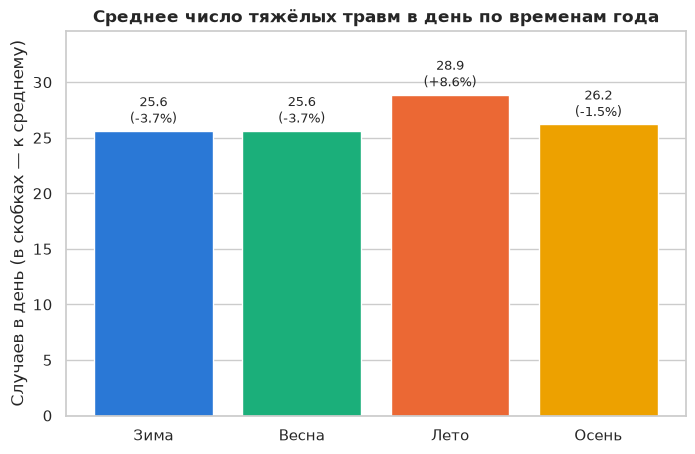

In [13]:
for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar([SEASONS[s][k] for s in seas.index], seas["per_day"],
                  color=[SEASON_COLORS[s] for s in seas.index])
    ax.bar_label(bars, labels=[f"{v:.1f}\n({d:+.1f}%)" for v, d in zip(seas["per_day"], seas["vs_mean_pct"])],
                 padding=3, fontsize=9)
    ax.set_ylim(0, seas["per_day"].max() * 1.2)
    ax.set_title(tr("Среднее число тяжёлых травм в день по временам года",
                    "Average severe injuries per day by season", lang))
    ax.set_ylabel(tr("Случаев в день (в скобках — к среднему)", "Cases per day (vs. overall mean)", lang))
    ax.grid(axis="x", visible=False)
    finish(fig, "04_6_seasons", lang)

## 4.7. Разложение ряда: тренд и сезонная волна (STL)

Помесячный ряд «случаев в день» (131 месяц) раскладывается на тренд, сезонную составляющую и остаток. Это отделяет сезонные колебания от провала 2020 года и общей динамики.

Сила сезонности (0 — нет, 1 — ряд целиком сезонный): 0.63
Размах сезонной волны: 7.46 случая в день


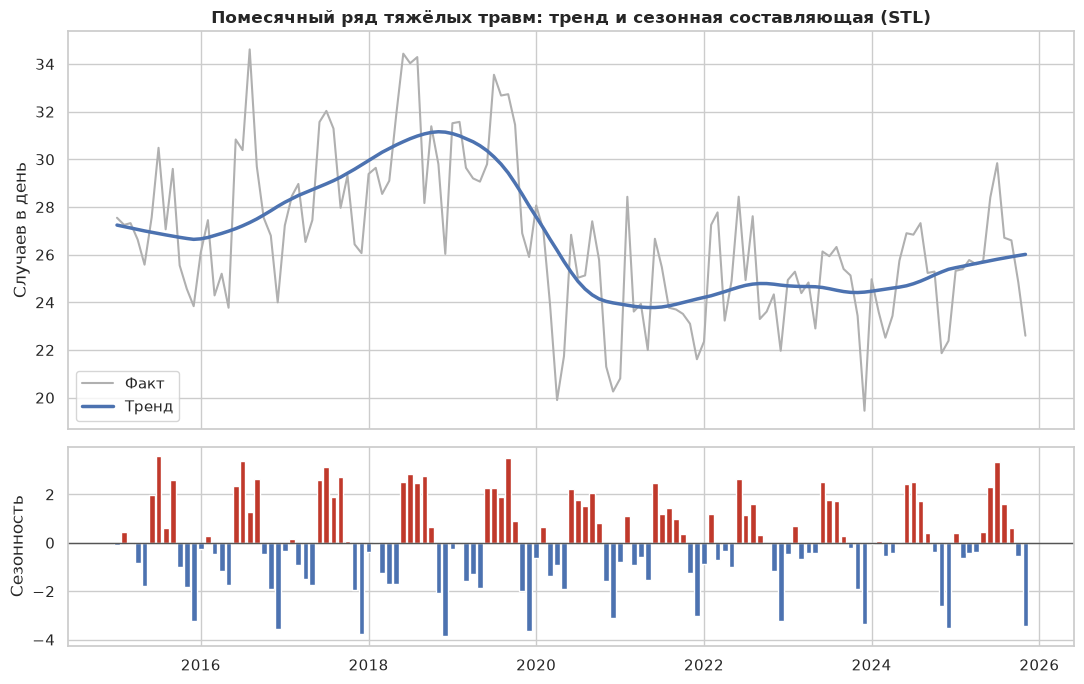

In [14]:
series = (cases.set_index("event_date").resample("MS").size()
          / days.set_index("date").resample("MS").size())
stl = STL(series, period=12, robust=True).fit()
strength = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f"Сила сезонности (0 — нет, 1 — ряд целиком сезонный): {strength:.2f}")
print(f"Размах сезонной волны: {stl.seasonal.max() - stl.seasonal.min():.2f} случая в день")

for lang in LANGS:
    fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    axes[0].plot(series.index, series, color="#b0b0b0", lw=1.5, label=tr("Факт", "Observed", lang))
    axes[0].plot(stl.trend.index, stl.trend, color=MAIN, lw=2.5, label=tr("Тренд", "Trend", lang))
    axes[0].set_ylabel(tr("Случаев в день", "Cases per day", lang))
    axes[0].legend(loc="lower left")
    axes[0].set_title(tr("Помесячный ряд тяжёлых травм: тренд и сезонная составляющая (STL)",
                         "Monthly severe injuries: trend and seasonal component (STL)", lang))
    axes[1].bar(stl.seasonal.index, stl.seasonal, width=25,
                color=np.where(stl.seasonal > 0, ACCENT, MAIN))
    axes[1].axhline(0, color="#555555", lw=1)
    axes[1].set_ylabel(tr("Сезонность", "Seasonal", lang))
    fig.tight_layout()
    finish(fig, "04_7_stl", lang)

## 4.8. Какие причины дают сезонные пики

Для отдельных групп причин — среднее число случаев в день по месяцам. У каждой группы своя шкала: важна форма кривой, а не уровень.

- **Жара** — категория травмы «Тепловой удар / перегрев» (см. `06_nature`);
- **Лёд, снег** — источник или вторичный источник *Ice, sleet, snow*;
- **Падения на одном уровне** и **падения с высоты** — типы происшествий 42x/43x и 41x/43x по названию;
- **Контакт с оборудованием**, **транспорт** — разделы типа происшествия 6 и 2.

In [15]:
cases["heat"] = cases["nature"].map(lambda t: nature_category(t)[0] == "Тепловой удар / перегрев")
cases["ice"] = (cases["source"].str.contains("ice, sleet, snow", case=False)
                | cases["secondary"].fillna("").str.contains("ice, sleet, snow", case=False))
ev_title = query("SELECT code AS event_code, title AS event FROM event_lookup")
cases = cases.merge(ev_title, on="event_code", how="left")
cases["fall_same"] = cases["event"].str.contains("fall on same level|slip|trip", case=False) & (cases["event_div"] == "4")
cases["fall_lower"] = cases["event"].str.contains("fall.* to lower level|fall from", case=False) & (cases["event_div"] == "4")
cases["contact"] = cases["event_div"] == "6"
cases["transport"] = cases["event_div"] == "2"

CAUSES = {
    "heat": ("Жара (перегрев)", "Heat illness"),
    "ice": ("Лёд, снег", "Ice, sleet, snow"),
    "fall_same": ("Падения на одном уровне", "Falls on same level"),
    "fall_lower": ("Падения с высоты", "Falls to lower level"),
    "contact": ("Контакт с оборудованием", "Contact with objects, equipment"),
    "transport": ("Транспортные происшествия", "Transportation incidents"),
}
month_all_days = days.groupby("month").size()
cause_month = cases.groupby("month")[list(CAUSES)].sum().div(month_all_days, axis=0)
cause_idx = 100 * cause_month / cause_month.mean()

summary = pd.DataFrame({
    "cases": cases[list(CAUSES)].sum(),
    "peak_month": cause_month.idxmax().map(lambda m: MONTHS[m][0]),
    "peak_index": cause_idx.max(),
    "low_month": cause_month.idxmin().map(lambda m: MONTHS[m][0]),
    "low_index": cause_idx.min(),
    "summer_share": [100 * cases.loc[cases[c], "season"].eq("summer").mean() for c in CAUSES],
    "winter_share": [100 * cases.loc[cases[c], "season"].eq("winter").mean() for c in CAUSES],
})
summary.insert(0, "cause_ru", [CAUSES[c][0] for c in summary.index])
summary.round(1).to_csv(TABLES_DIR / "04_8_seasonal_causes.csv", encoding="utf-8-sig")
cause_idx.round(0).set_axis([CAUSES[c][0] for c in CAUSES], axis=1).to_csv(
    TABLES_DIR / "04_8_seasonal_causes_index.csv", encoding="utf-8-sig")
summary.round(1)

,cause_ru,cases,peak_month,peak_index,low_month,low_index,summer_share,winter_share
heat,Жара (перегрев),2658,Июл,421.1,Дек,2.0,79.0,0.6
ice,"Лёд, снег",1788,Фев,399.6,Июл,0.6,0.3,77.7
fall_same,Падения на одном уровне,13813,Фев,150.5,Май,81.2,22.4,32.6
fall_lower,Падения с высоты,17046,Авг,105.1,Дек,89.3,26.2,23.2
contact,Контакт с оборудованием,48445,Окт,107.3,Дек,85.2,26.5,22.6
transport,Транспортные происшествия,9402,Авг,113.5,Янв,82.3,28.0,20.9


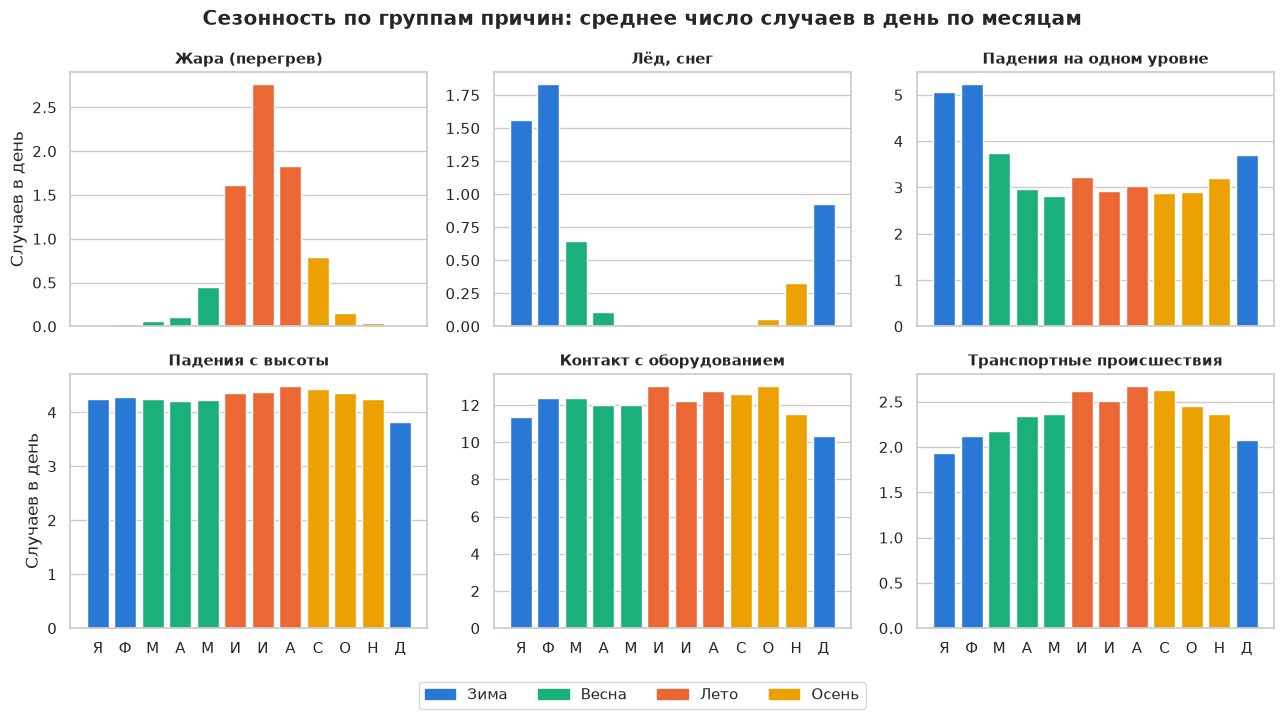

In [16]:
for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
    for ax, c in zip(axes.flat, CAUSES):
        s = cause_month[c]
        ax.bar(s.index, s, color=[SEASON_COLORS[MONTH_TO_SEASON[m]] for m in s.index])
        ax.set_title(CAUSES[c][k], fontsize=11)
        ax.set_xticks(range(1, 13), [MONTHS[m][k][0] for m in range(1, 13)])
        ax.grid(axis="x", visible=False)
    for ax in axes[:, 0]:
        ax.set_ylabel(tr("Случаев в день", "Cases per day", lang))
    fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in SEASON_COLORS.values()],
               labels=[SEASONS[s][k] for s in SEASON_COLORS], loc="lower center", ncols=4,
               bbox_to_anchor=(0.5, -0.03))
    fig.suptitle(tr("Сезонность по группам причин: среднее число случаев в день по месяцам",
                    "Seasonality by cause group: average cases per day by month", lang), fontweight="bold")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    finish(fig, "04_8_seasonal_causes", lang)

### Раздел типа происшествия × сезон

Стандартизованные остатки χ²: |r| > 2 — сезон заметно отклоняется от ожидаемого для этого раздела (красный — больше ожидаемого, синий — меньше).

Раздел происшествия × сезон: χ² = 1 819, df = 21, p = 0.00e+00, V Крамера = 0.076


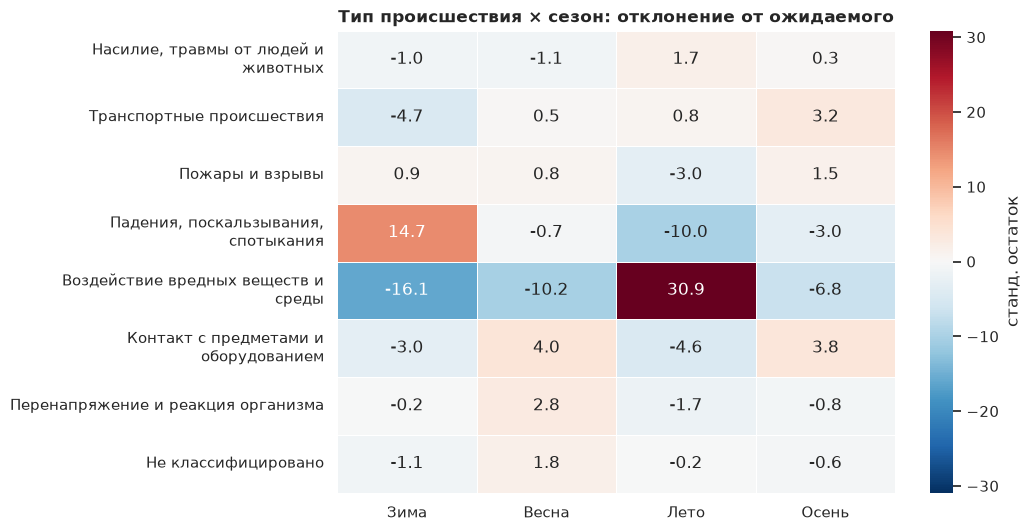

In [17]:
ct = pd.crosstab(cases["event_div"], cases["season"])[list(SEASONS)]
chi2, p, dof, v, expected = cramers_v(ct)
print(f"Раздел происшествия × сезон: χ² = {num(chi2)}, df = {dof}, p = {p:.2e}, V Крамера = {v:.3f}")
resid = (ct - expected) / np.sqrt(expected)
resid.round(1).to_csv(TABLES_DIR / "04_8_event_season_residuals.csv", encoding="utf-8-sig")

for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(9, 6))
    lim = np.abs(resid.to_numpy()).max()
    sns.heatmap(resid, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-lim, vmax=lim,
                linewidths=0.5, linecolor="white", ax=ax,
                cbar_kws={"label": tr("станд. остаток", "std. residual", lang)},
                xticklabels=[SEASONS[s][k] for s in resid.columns],
                yticklabels=[wrap(EVENT_DIVISIONS[d][k], 34) for d in resid.index])
    ax.set_title(tr("Тип происшествия × сезон: отклонение от ожидаемого",
                    "Event division × season: deviation from expected", lang))
    ax.set_xlabel("")
    ax.set_ylabel("")
    finish(fig, "04_8_event_season_residuals", lang)

## 4.9. Дни недели

Среднее число случаев в день для каждого дня недели; χ² — распределены ли случаи пропорционально числу дней.

In [18]:
wd_days = days.groupby("weekday").size()
wd = cases.groupby("weekday").size().rename("cases").to_frame()
wd["days"] = wd_days
wd["per_day"] = wd["cases"] / wd["days"]
wd["pct_amputation"] = 100 * cases.groupby("weekday")["amputation"].mean()
wd.insert(0, "weekday_ru", [WEEKDAYS[d][0] for d in wd.index])
chi2, p = stats.chisquare(wd["cases"], wd_days / wd_days.sum() * N)
print(f"Равномерность по дням недели: χ² = {num(chi2)}, df = 6, p = {p:.2e}")
print(f"Будний день в среднем: {wd.loc[1:5, 'per_day'].mean():.1f}, выходной: {wd.loc[6:7, 'per_day'].mean():.1f} случая")
wd.round(2).to_csv(TABLES_DIR / "04_9_weekdays.csv", encoding="utf-8-sig")
wd.round(2)

Равномерность по дням недели: χ² = 15 682, df = 6, p = 0.00e+00
Будний день в среднем: 32.9, выходной: 10.8 случая


,weekday_ru,cases,days,per_day,pct_amputation
weekday,,,,,
1,Пн,18606,569,32.70,26.39
2,Вт,19790,569,34.78,25.96
3,Ср,19839,569,34.87,26.67
4,Чт,19008,570,33.35,27.03
5,Пт,16398,570,28.77,27.34
6,Сб,7581,570,13.30,25.26
7,Вс,4774,570,8.38,22.73


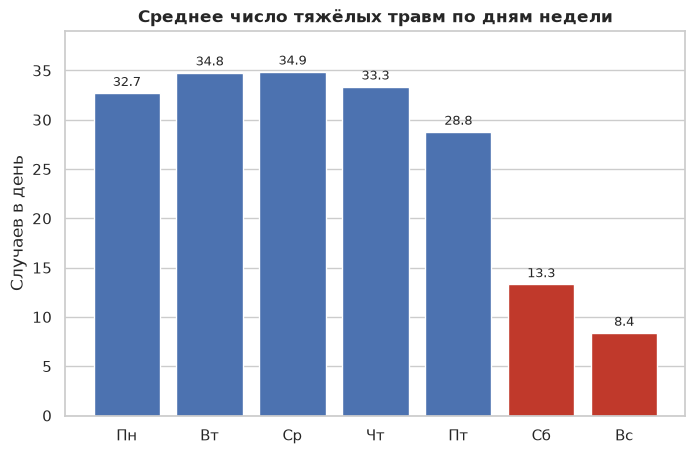

In [19]:
for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar([WEEKDAYS[d][k] for d in wd.index], wd["per_day"],
                  color=[MAIN] * 5 + [ACCENT] * 2)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in wd["per_day"]], padding=3, fontsize=9)
    ax.set_title(tr("Среднее число тяжёлых травм по дням недели",
                    "Average severe injuries by day of week", lang))
    ax.set_ylabel(tr("Случаев в день", "Cases per day", lang))
    ax.set_ylim(0, wd["per_day"].max() * 1.12)
    ax.grid(axis="x", visible=False)
    finish(fig, "04_9_weekdays", lang)

## Выводы

1. **Число тяжёлых травм снизилось после 2020 года.** В 2015–2019 годах в среднем было 876 случаев в месяц (пик — 930 в 2018 году), в 2021–2025 — 754, то есть на 13,9% меньше (t Уэлча = 8,6, p < 0,001). Провал 2020 года (−19,5%) совпадает с пандемией, после него прежний уровень не восстановился; в 2025 году среднее в месяц выросло до 792.
2. **Тяжесть по годам почти не меняется:** госпитализация — 80–82% случаев, ампутация — 25–28%. Различия между годами формально значимы, но пренебрежимо малы (V Крамера < 0,02); доля госпитализаций растёт на 0,14 п.п. в год.
3. **Сезонность выражена и устойчива.** Случаи распределены по месяцам неравномерно (χ² = 440, p < 0,001), сила сезонности по STL — 0,63. Лето — пик: 28,9 случая в день, на 8,6% выше среднего; зима и весна — на 3,7% ниже (Краскел–Уоллис H = 19,5, p < 0,001). Максимум — июль (индекс 109), минимум — декабрь (87, праздники и меньше рабочих дней), ещё один провал — ноябрь.
4. **Сезонные пики дают разные причины.** Тепловой удар: 79% случаев летом, в июле в 4 раза больше среднего. Лёд и снег: 78% — зимой, пик в феврале. Падения на одном уровне тоже зимние (февраль — 150% от среднего, поскальзывание). Транспортные происшествия и падения с высоты чуть чаще летом, контакт с оборудованием почти не зависит от сезона. Связь раздела происшествия с сезоном слабая в целом (V Крамера = 0,08), но с крупными остатками: воздействие вредной среды летом (+31), падения зимой (+15).
5. **Дни недели.** В будний день в среднем 32,9 тяжёлой травмы, в выходной — 10,8 (в воскресенье — 8,4): риск определяется временем работы, а не календарём. Пятница уже ниже середины недели (28,8).
6. **Секторы по годам.** Относительно 2015 года число случаев в месяц в обрабатывающей промышленности упало на 16%, в строительстве и транспорте вернулось к уровню 2015 года, а в рознице (+17%) и здравоохранении (+12%) — выросло.